# T5: Random search versus aging evolution
The topology space has $5^6=15,625$ cells. All scores are benchmark lookups:
CIFAR-10 validation (`cifar10-valid`), horizon 200, averaged across benchmark
training seeds (`is_random=False`). Search seeds are 42, 43 and 44.


In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "code"))


In [1]:
from common import *
from collections import deque

OPS = ["none", "skip_connect", "nor_conv_1x1", "nor_conv_3x3", "avg_pool_3x3"]
EDGES = [(0, 1), (0, 2), (1, 2), (0, 3), (1, 3), (2, 3)]


def encode(arch):
    return "+".join(
        "|"
        + "|".join(f"{OPS[arch[e]]}~{i}" for e, (i, d) in enumerate(EDGES) if d == j)
        + "|"
        for j in range(1, 4)
    )


def random_arch(rng):
    return tuple(rng.randrange(5) for _ in range(6))


print("Space size:", 5**6, "Example:", encode((0, 1, 2, 3, 4, 1)))


Space size: 15625 Example: |none~0|+|skip_connect~0|nor_conv_1x1~1|+|nor_conv_3x3~0|avg_pool_3x3~1|skip_connect~2|


## Load a compact validation-only lookup extracted from official NATS-Bench
The conversion script discards all unused datasets and training curves.


In [2]:
lookup = json.loads((ROOT / "data" / "nats_validation.json").read_text())


def score(arch):
    return lookup[encode(arch)]


## Random search and FIFO aging evolution
Population initialization counts toward the 100 evaluations. Tournament size
is three, population size ten, and mutation always changes exactly one edge.
Duplicates are permitted and still consume an evaluation in both methods.


In [3]:
def search(seed, evolution=False):
    rng = random.Random(seed)
    population = deque()
    history = []
    best = -float("inf")
    for evaluation in range(100):
        parent = None
        changed = None
        if not evolution or len(population) < 10:
            arch = random_arch(rng)
        else:
            parent = max(
                rng.sample(list(population), 3), key=lambda member: member["accuracy"]
            )
            child = list(parent["architecture"])
            changed = rng.randrange(6)
            child[changed] = rng.choice([o for o in range(5) if o != child[changed]])
            arch = tuple(child)
            assert sum(a != b for a, b in zip(arch, parent["architecture"])) == 1
        value = score(arch)
        best = max(best, value)
        record = {
            "evaluation": evaluation + 1,
            "architecture": arch,
            "encoding": encode(arch),
            "accuracy": value,
            "best_ever": best,
        }
        if evolution:
            population.append(record)
            if len(population) > 10:
                population.popleft()
            assert len(population) == min(evaluation + 1, 10)
            record.update(
                population_size=len(population),
                population_best=max(m["accuracy"] for m in population),
                parent_evaluation=parent["evaluation"] if parent else None,
                mutated_edge=changed,
            )
        history.append(record)
    return history


runs = {
    method: {
        str(seed): search(seed, method == "aging_evolution") for seed in [42, 43, 44]
    }
    for method in ["random", "aging_evolution"]
}
summary = {}
for method, seed_runs in runs.items():
    values = [h[-1]["best_ever"] for h in seed_runs.values()]
    summary[method] = {
        "best": max(values),
        "mean": float(np.mean(values)),
        "std": float(np.std(values, ddof=0)),
        "per_seed": values,
        "evaluations_per_run": 100,
        "runs": 3,
    }
save_json(
    "task5",
    {
        "runs": runs,
        "summary": summary,
        "metric": "cifar10-valid/valid-accuracy",
        "hp": "200",
        "benchmark_seeds": "mean",
        "space_size": 5**6,
    },
)
print(summary)


{'random': {'best': 91.18799997924805, 'mean': 91.05133332112631, 'std': 0.1052277898778946, 'per_seed': [90.93199999145509, 91.03399999267577, 91.18799997924805], 'evaluations_per_run': 100, 'runs': 3}, 'aging_evolution': {'best': 91.51599999023438, 'mean': 91.33222221177842, 'std': 0.17181930999191308, 'per_seed': [91.37799998168944, 91.51599999023438, 91.10266666341145], 'evaluations_per_run': 100, 'runs': 3}}


## Search curves and population aging


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for method, seed_runs in runs.items():
    for seed, h in seed_runs.items():
        axes[0].plot(
            range(1, 101), [r["best_ever"] for r in h], label=f"{method}, {seed}"
        )
for seed, h in runs["aging_evolution"].items():
    axes[1].plot(
        range(1, 101), [r["population_best"] for r in h], label=f"Population, {seed}"
    )
    axes[1].plot(
        range(1, 101),
        [r["best_ever"] for r in h],
        linestyle="--",
        alpha=0.6,
        label=f"Ever, {seed}",
    )
for ax in axes:
    ax.set(
        xlabel="Architecture evaluations", ylabel="Benchmark validation accuracy (%)"
    )
    ax.legend(fontsize=6)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t5_search.png", dpi=150)
plt.close(fig)


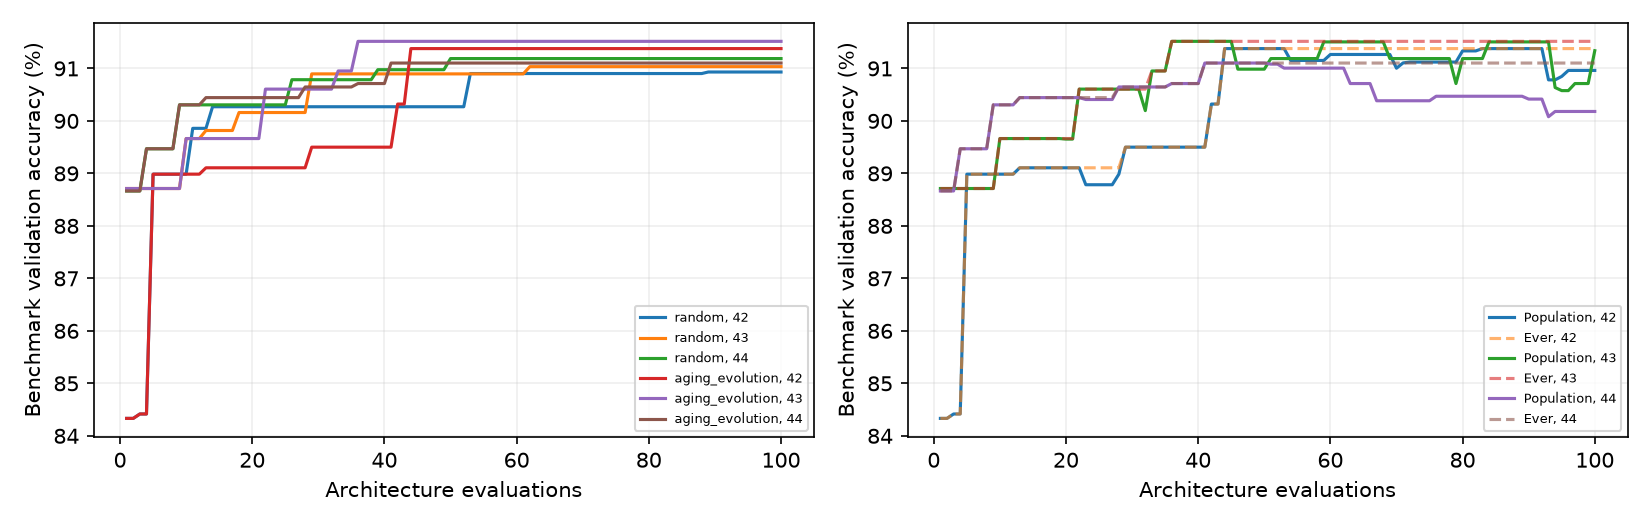

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(project_root / "figures" / "t5_search.png")))


# Analysis

## T5.1: Random Search

**Q1.** Report the search-space size, one example architecture, the best result for each seed, and best-so-far accuracy curves.

**Answer:**

The space has six edges and five choices per edge:

$$|\mathcal S|=5^6=15{,}625.$$

Example encoding: `|none~0|+|skip_connect~0|nor_conv_1x1~1|+|nor_conv_3x3~0|avg_pool_3x3~1|skip_connect~2|`. Each edge is sampled uniformly and independently. Each run evaluates 100 architectures; duplicates are allowed and count against the budget. Scores are official NATS-Bench topology-space CIFAR-10 validation lookups (`cifar10-valid`, `valid-accuracy`, hp='200', mean over available benchmark training seeds with `is_random=False`). They are not new GPU training measurements. `data/nats_validation.json` contains the compact 15,625-entry lookup derived from the official benchmark file.

| Search seed | Random best (%) | Evolution best (%) |
| --- | --- | --- |
| 42 | 90.93 | 91.38 |
| 43 | 91.03 | 91.52 |
| 44 | 91.19 | 91.10 |

![Best-so-far validation accuracy versus evaluation count; evolution population-best curves can decrease.](../figures/t5_search.png)

Best-so-far validation accuracy versus evaluation count; evolution population-best curves can decrease.


## T5.2: Aging Evolution

**Q1.** Show pseudocode or an execution trace, population-size checks, and curves for current population best and best-ever accuracy. Can the best architecture currently in the population become worse over time? Explain why.

**Answer:**

Pseudocode:

```text
population = FIFO queue; best_ever = -infinity
for evaluation = 1,...,100:
    if population has fewer than 10 members: sample a random cell
    else:
        sample 3 distinct population members uniformly
        choose the one with highest validation accuracy
        change one random edge to one of its other 4 operations
    look up validation accuracy; update best_ever
    append the new cell; remove the oldest if size exceeds 10
    record population_best and best_ever
```

Assertions verify population size equals min(evaluations, 10) and every mutation changes exactly one edge. The ten initialization evaluations are included in the 100-evaluation budget. All three runs passed. Full traces, parent evaluation IDs and mutated edges are in `results/task5.json`. The current population's best can fall when its strongest member ages out, even if it remains globally best. The best-ever statistic cannot decrease because it is the running maximum across all evaluated candidates.


## T5.3: Compare the Search Methods

**Q1.** Compare random search and aging evolution using best-so-far validation accuracy against the number of evaluations. Report the best, mean, and standard deviation across three runs. Which method performed better under the same evaluation budget?

**Answer:**

| Method | Best validation (%) | Mean best (%) | Std. dev. (pp) | Evaluations per run |
| --- | --- | --- | --- | --- |
| Random search | 91.19 | 91.05 | 0.11 | 100 |
| Aging evolution | 91.52 | 91.33 | 0.17 | 100 |
Statistics summarize the final best-so-far score across three search seeds (42, 43, 44); standard deviation uses ddof=0. Each method used 300 evaluations in total. Aging evolution's mean was 0.281 percentage points higher under the same per-run budget. This supports evolution in these three runs; the small sample and shared benchmark do not establish universal superiority. Every lookup uses the same metric and training horizon, with no CIFAR-10 test accuracy used to guide search.
